# 3D Discontinuous Inverse SPILS-Net GNN Result Analysis (Forces $\to$ Displacements)

This notebook analyzes 3D inverse surrogate model performance for SPILS-Net with Graph Neural Network (GNN) entry and exit layers on a **discontinuous coupling interface** in 3D elastoplastic domain simulations.

**Domain Geometry (Column with Horizontal Through-Hole):**
- The column is **one single connected piece**: a 3D vertical cylinder (radius $R = 25.0\text{ mm}$, height $H = 100.0\text{ mm}$).
- A **horizontal cylindrical hole** ($R_{\text{hole}} = 10.0\text{ mm}$) passes straight through the middle of the column along the $y$-axis at $z = 50.0\text{ mm}$.
- **Discontinuous Coupling Interface ($z = 50.0\text{ mm}$):** The through-hole cuts away the central strip $|x| \le 10.0\text{ mm}$, disconnecting the interface into **two lateral sections** ($x \le -10\text{ mm}$ and $x \ge 10\text{ mm}$).
- The bottom face ($z = 0$) is driven by sinusoidal displacement, while the top face ($z = 100$) is clamped by a fixed Dirichlet boundary condition.

**Inverse Formulation:**
- **Input ($X$):** Interface Forces/Tractions ($F_x, F_y, F_z$ per node across both interface sections)
- **Predicted Output ($Y$):** Interface Displacements ($u_x, u_y, u_z$ per node across both interface sections)
- **Internal State ($Z$):** PCA-reduced equivalent plastic strain field ($\bar{\varepsilon}^p$)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from mpl_toolkits.mplot3d import Axes3D  # Register 3D projection
from pathlib import Path

# Publication quality styling matching LaTeX standards
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "savefig.dpi": 300,
    "figure.autolayout": False,
})

In [2]:
colors_ordered = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown",
    "tab:pink",
    "tab:cyan",
    "tab:olive"
]

internal_state_color = "tab:olive"

def make_plot_3d(ax, data, node_indices, dof_offset=0, n_dofs=3, linestyle='-', **kwargs):
    """
    Plots time-series data for specified node indices and DOF offset.
    
    Args:
        ax: Matplotlib axis.
        data: Array of shape [num_steps, num_nodes * n_dofs].
        node_indices: List of node indices to plot.
        dof_offset: DOF offset (0 for X, 1 for Y, 2 for Z).
        n_dofs: Number of DOFs per node (default 3 for 3D).
    """
    for i, node_idx in enumerate(node_indices):
        feature_idx = node_idx * n_dofs + dof_offset
        if feature_idx < data.shape[1]:
            ax.plot(
                data[:, feature_idx],
                linestyle=linestyle,
                color=colors_ordered[i % len(colors_ordered)],
                **kwargs
            )

## 1. Load Simulation Results & Discontinuous Mesh Topology

In [3]:
# Configuration matching the simulation run
law = "plastic"
method = "spils_net_gnn"
version = "01"
freq = 1000

results_dir = Path("results_3d_disc_inv")
if not results_dir.exists() and Path("workspace/results_3d_disc_inv").exists():
    results_dir = Path("workspace/results_3d_disc_inv")

data_dir = Path("training_data_3d_disc_inv")
if not data_dir.exists() and Path("workspace/training_data_3d_disc_inv").exists():
    data_dir = Path("workspace/training_data_3d_disc_inv")

topo_path = data_dir / f"interface_topology_3d_{law}.npz"
if not topo_path.exists():
    topo_path = data_dir / "interface_topology_3d_plastic.npz"

suffix_tct = f"3d_{law}_disc_f{freq}"
suffix_sm  = f"3d_{law}_{method}_disc_v{version}_f{freq}"

# Target file paths from applied simulation
tct_file_in       = results_dir / f"tct_results_in_{suffix_tct}.npy"
tct_file_out      = results_dir / f"tct_results_out_{suffix_tct}.npy"
tct_file_internal = results_dir / f"tct_results_internal_{suffix_tct}.npy"

sm_in_file       = results_dir / f"sm_results_in_{suffix_sm}.npy"
sm_out_file      = results_dir / f"sm_results_out_{suffix_sm}.npy"
sm_internal_file = results_dir / f"sm_results_internal_{suffix_sm}.npy"
sm_error_file    = results_dir / f"sm_results_error_{suffix_sm}.npy"

# Strict check: ensure application output files exist
required_files = [tct_file_in, tct_file_out, sm_in_file, sm_out_file, sm_error_file]
missing = [str(f) for f in required_files if not f.exists()]
if missing:
    raise FileNotFoundError(
        "Missing applied simulation output files:
  " + "
  ".join(missing) +
        "
Please run docker compose run --rm spils-net /bin/bash -c "cd workspace && python3 create_predictor_3d_disc.py --method spils_net_gnn --apply " first to generate these results."
    )

# Load FEM Ground Truth Results
tct_results_in       = np.load(tct_file_in)
tct_results_out      = np.load(tct_file_out)
tct_results_internal = np.load(tct_file_internal) if tct_file_internal.exists() else np.zeros(tct_results_in.shape[0])
has_true_data        = True

# Load Applied Surrogate Model Prediction Results
sm_results_in        = np.load(sm_in_file)
sm_results_out       = np.load(sm_out_file)
sm_results_internal  = np.load(sm_internal_file) if sm_internal_file.exists() else np.zeros(sm_results_in.shape[0])
sm_results_error     = np.load(sm_error_file)

# Ensure displacement shape has only displacement DOFs
n_dofs = sm_results_in.shape[-1]
if tct_results_out.shape[-1] > n_dofs:
    tct_results_out = tct_results_out[:, :n_dofs]
if sm_results_out.shape[-1] > n_dofs:
    sm_results_out = sm_results_out[:, :n_dofs]

# Trim length matching
min_len = min(tct_results_in.shape[0], sm_results_in.shape[0], tct_results_out.shape[0], sm_results_out.shape[0])
if len(tct_results_internal) > 0 and len(sm_results_internal) > 0:
    min_len = min(min_len, tct_results_internal.shape[0], sm_results_internal.shape[0])
tct_results_in       = tct_results_in[:min_len]
tct_results_out      = tct_results_out[:min_len]
tct_results_internal = tct_results_internal[:min_len]
sm_results_in        = sm_results_in[:min_len]
sm_results_out       = sm_results_out[:min_len]
sm_results_internal  = sm_results_internal[:min_len]
sm_results_error     = sm_results_error[:min_len]

# Load interface mesh topology
if topo_path.exists():
    topo_data = np.load(topo_path)
    node_coords = np.asarray(topo_data["coords"], dtype=float)
    connectivity = np.asarray(topo_data["connectivity"], dtype=int)
    num_nodes = node_coords.shape[0]
else:
    num_nodes = sm_results_out.shape[1] // 3
    node_coords = None
    connectivity = None

print(f"Loaded 3D Discontinuous Results for {method.upper()} ({law}, v{version}, {freq}Hz):")
print(f"  Input Forces (In) shape          : {sm_results_in.shape}")
print(f"  Predicted Displacements (Out)    : {sm_results_out.shape}")
print(f"  Internal State shape             : {sm_results_internal.shape}")
print(f"  Relative Displacement Error shape: {sm_results_error.shape}")
print(f"  Has Full FEM Ground Truth        : {has_true_data}")
if has_true_data:
    print(f"  FEM Internal State shape         : {tct_results_internal.shape}")
if node_coords is not None:
    print(f"  Interface Nodes                  : {num_nodes} nodes, {connectivity.shape[0]} triangular faces")


Loaded 3D Discontinuous Results for SPILS_NET_GNN (plastic, v01, 1000Hz):
  Input Forces (In) shape          : (2000, 306)
  Predicted Displacements (Out)    : (2000, 306)
  Internal State shape             : (2000,)
  Relative Displacement Error shape: (2000,)
  Has Full FEM Ground Truth        : True
  Interface Nodes                  : 102 nodes, 150 triangular faces
  Section 1 (Left Side)            : 51 nodes (x < 0)
  Section 2 (Right Side)           : 51 nodes (x > 0)


## 2. 3D Column Geometry & Discontinuous Interface Visualization

Saved figure: figures/3d_interface_topology_disc.pdf


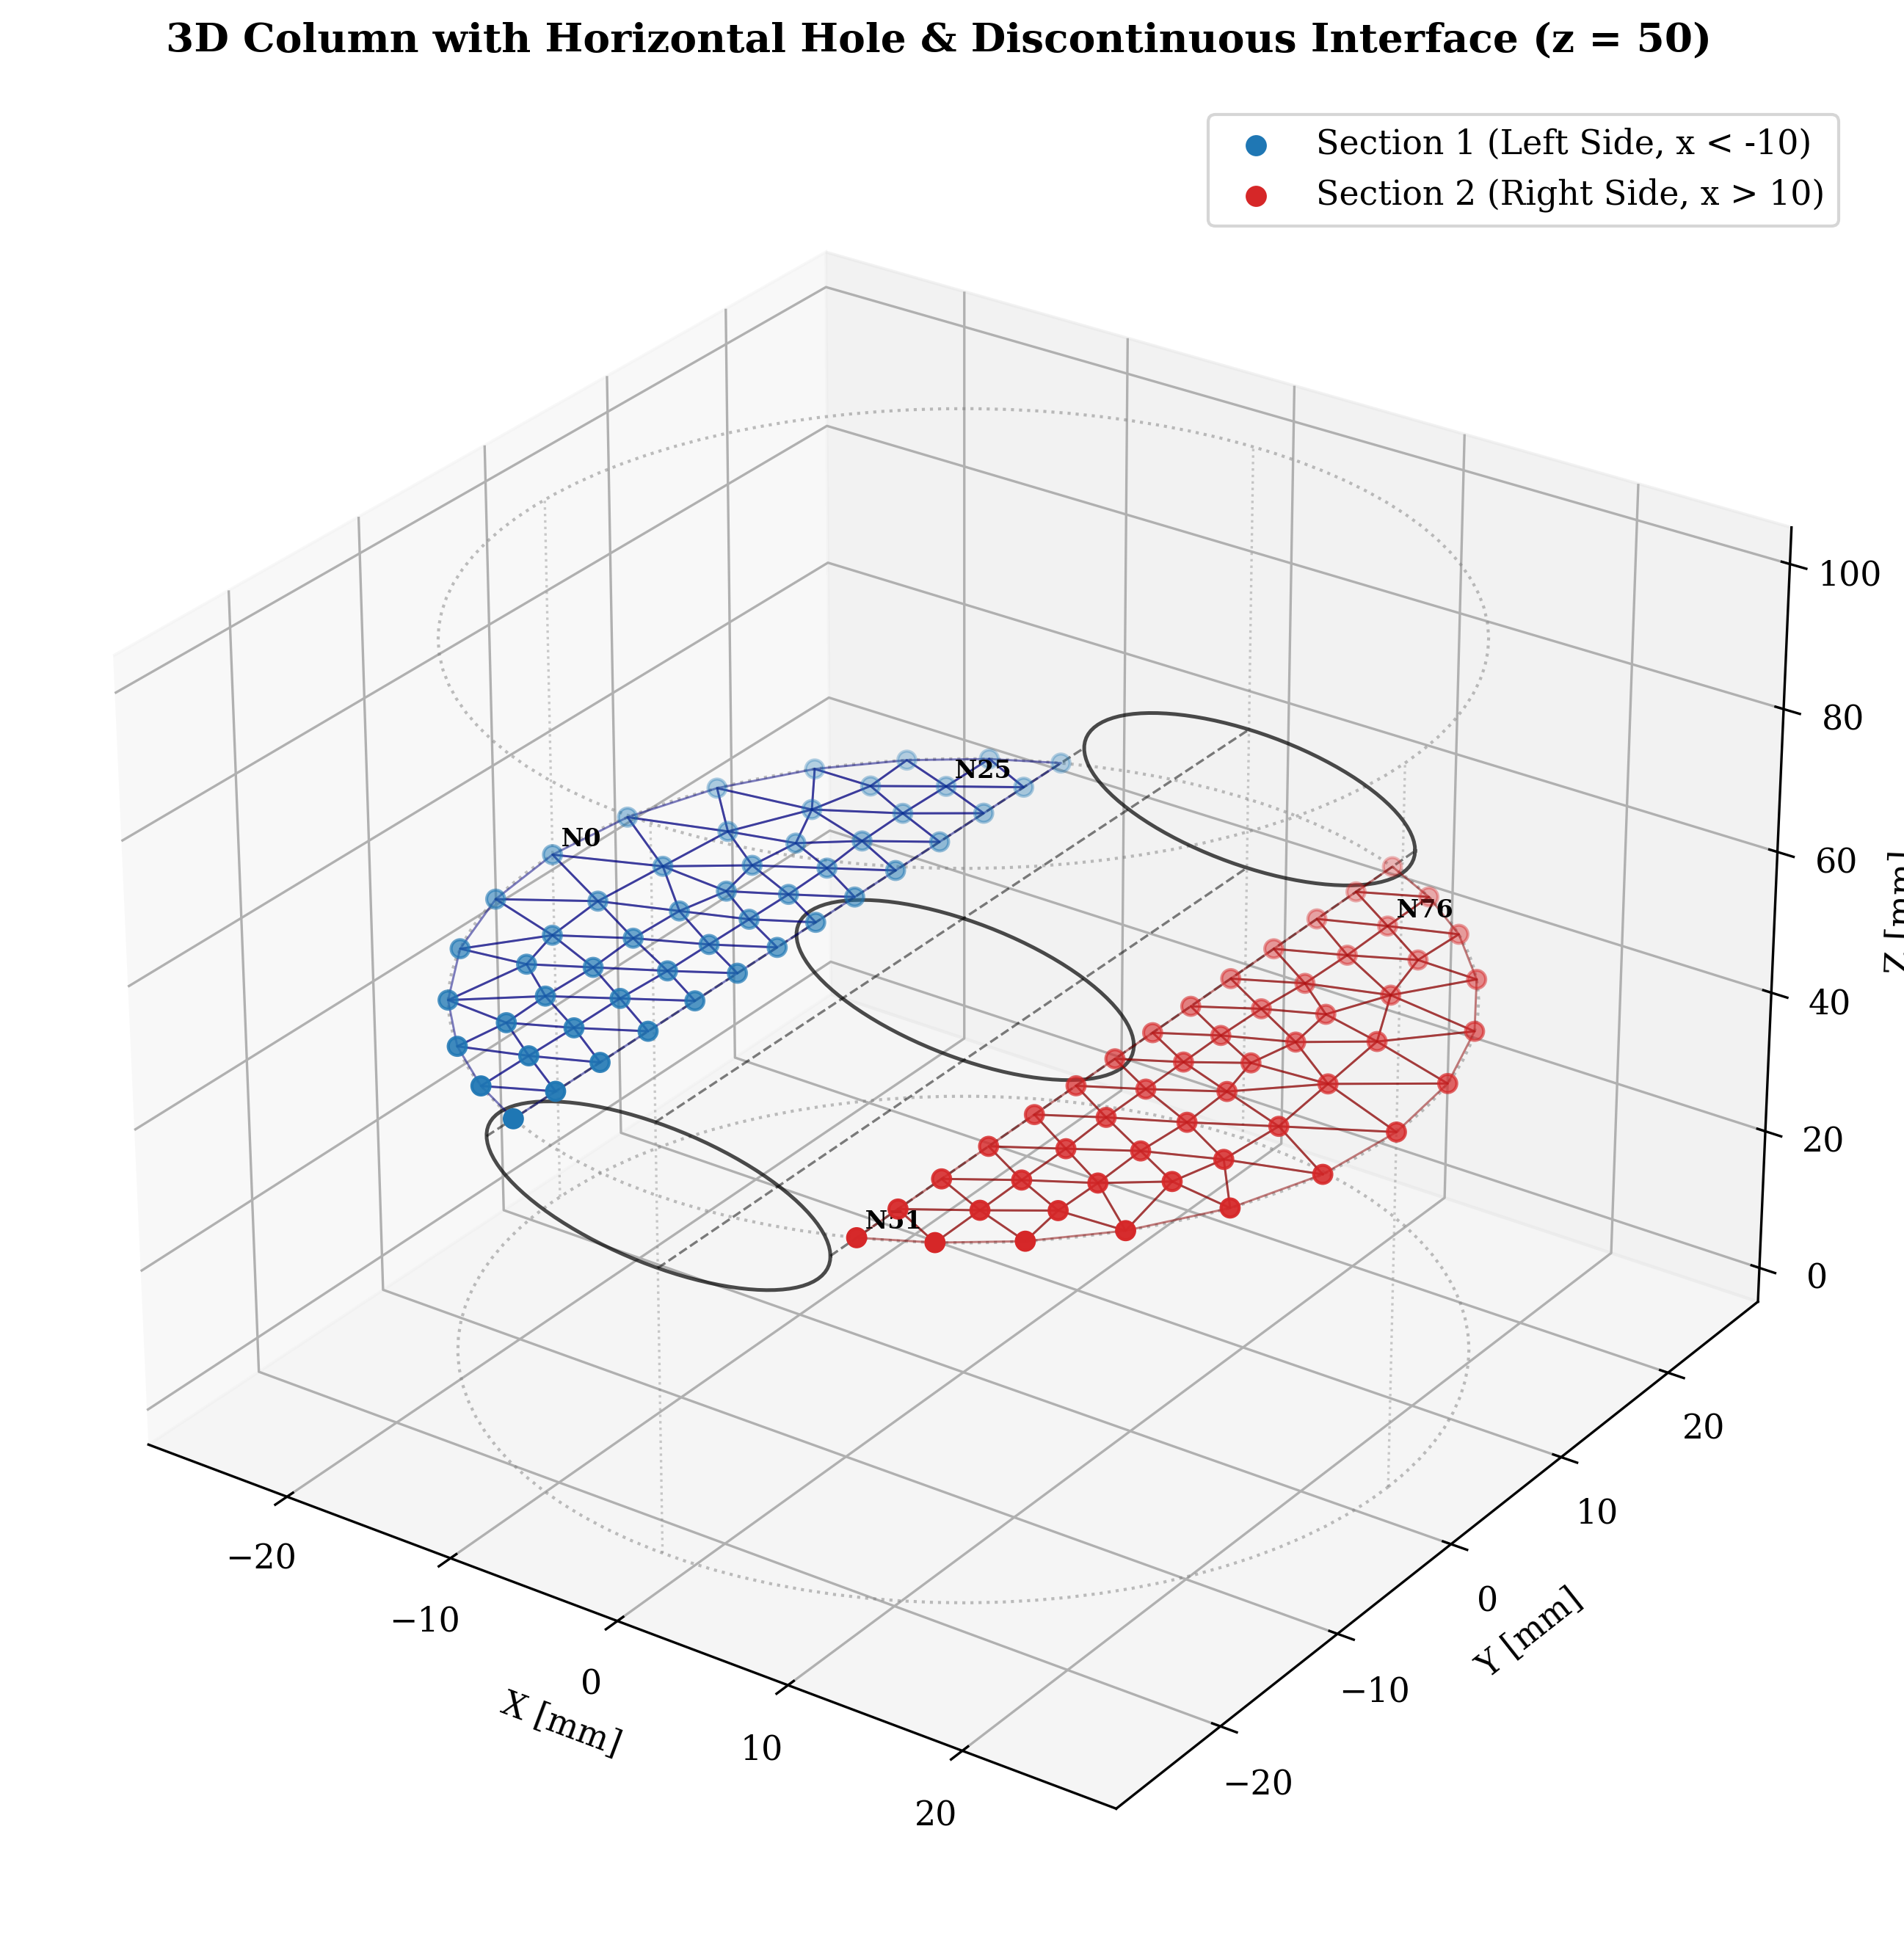

In [4]:
if node_coords is not None and connectivity is not None:
    fig = plt.figure(figsize=(10, 9), dpi=300)
    ax = fig.add_subplot(111, projection="3d")

    x, y, z = node_coords[:, 0], node_coords[:, 1], node_coords[:, 2]

    # 1. Draw outer cylindrical column boundary (R = 25, H = 100)
    theta_c = np.linspace(0, 2 * np.pi, 100)
    R_col = 25.0
    for z_lvl in [0.0, 50.0, 100.0]:
        ax.plot(R_col * np.cos(theta_c), R_col * np.sin(theta_c), np.full_like(theta_c, z_lvl), color="gray", linestyle=":", alpha=0.5, linewidth=1.0)
    for ang in [0, np.pi/2, np.pi, 3*np.pi/2]:
        ax.plot([R_col*np.cos(ang), R_col*np.cos(ang)], [R_col*np.sin(ang), R_col*np.sin(ang)], [0.0, 100.0], color="gray", linestyle=":", alpha=0.4, linewidth=0.8)

    # 2. Draw horizontal cylindrical through-hole (bored along y-axis at z=50, R_hole = 10)
    R_hole = 10.0
    theta_hole = np.linspace(0, 2 * np.pi, 100)
    for y_pos in [-R_col, 0.0, R_col]:
        h_x = R_hole * np.cos(theta_hole)
        h_z = 50.0 + R_hole * np.sin(theta_hole)
        ax.plot(h_x, np.full_like(theta_hole, y_pos), h_z, color="black", linestyle="-", alpha=0.7, linewidth=1.2)

    # Hole generator lines
    for ang in [0, np.pi/2, np.pi, 3*np.pi/2]:
        gx = R_hole * np.cos(ang)
        gz = 50.0 + R_hole * np.sin(ang)
        ax.plot([gx, gx], [-R_col, R_col], [gz, gz], color="black", linestyle="--", alpha=0.5, linewidth=0.8)

    # 3. Plot triangular facets on the interface (z = 50, left and right sides)
    for tri in connectivity:
        pts = node_coords[tri]
        tri_x = np.append(pts[:, 0], pts[0, 0])
        tri_y = np.append(pts[:, 1], pts[0, 1])
        tri_z = np.append(pts[:, 2], pts[0, 2])
        edge_color = "navy" if pts[0, 0] < 0 else "darkred"
        ax.plot(tri_x, tri_y, tri_z, color=edge_color, alpha=0.5, linewidth=0.7)

    # 4. Plot interface nodes (z = 50)
    is_left = x < 0
    ax.scatter(x[is_left], y[is_left], z[is_left], color="tab:blue", s=35, label="Section 1 (Left Side, x < -10)", depthshade=True)
    ax.scatter(x[~is_left], y[~is_left], z[~is_left], color="tab:red", s=35, label="Section 2 (Right Side, x > 10)", depthshade=True)

    # Annotate representative nodes
    sample_indices = [0, len(x)//4, len(x)//2, 3*len(x)//4]
    for idx in sample_indices:
        ax.text(x[idx], y[idx], z[idx] + 1.2, f" N{idx}", fontsize=8, color="black", weight="bold")

    ax.set_title("3D Column with Horizontal Hole & Discontinuous Interface (z = 50)", pad=15, weight="bold")
    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")
    ax.set_zlabel("Z [mm]")
    ax.set_zlim(-5, 105)
    ax.legend(loc="upper right", frameon=True)
    ax.view_init(elev=28, azim=-55)

    plt.tight_layout()
    Path("figures").mkdir(exist_ok=True)
    fig_path = Path("figures/3d_interface_topology_disc.pdf")
    plt.savefig(fig_path, bbox_inches="tight")
    print(f"Saved figure: {fig_path}")
    plt.show()
else:
    print("Topology coordinates not available for direct 3D visualization.")

## 3. Overlapped 3D Response Comparison Plot (Full FEM vs SPILS-Net GNN Prediction)

Here we compare the true vs predicted displacement response for sample interface nodes across both disconnected circular sections.

Saved figure: figures/06_spils_net_gnn_3d_disc_results_1000.pdf


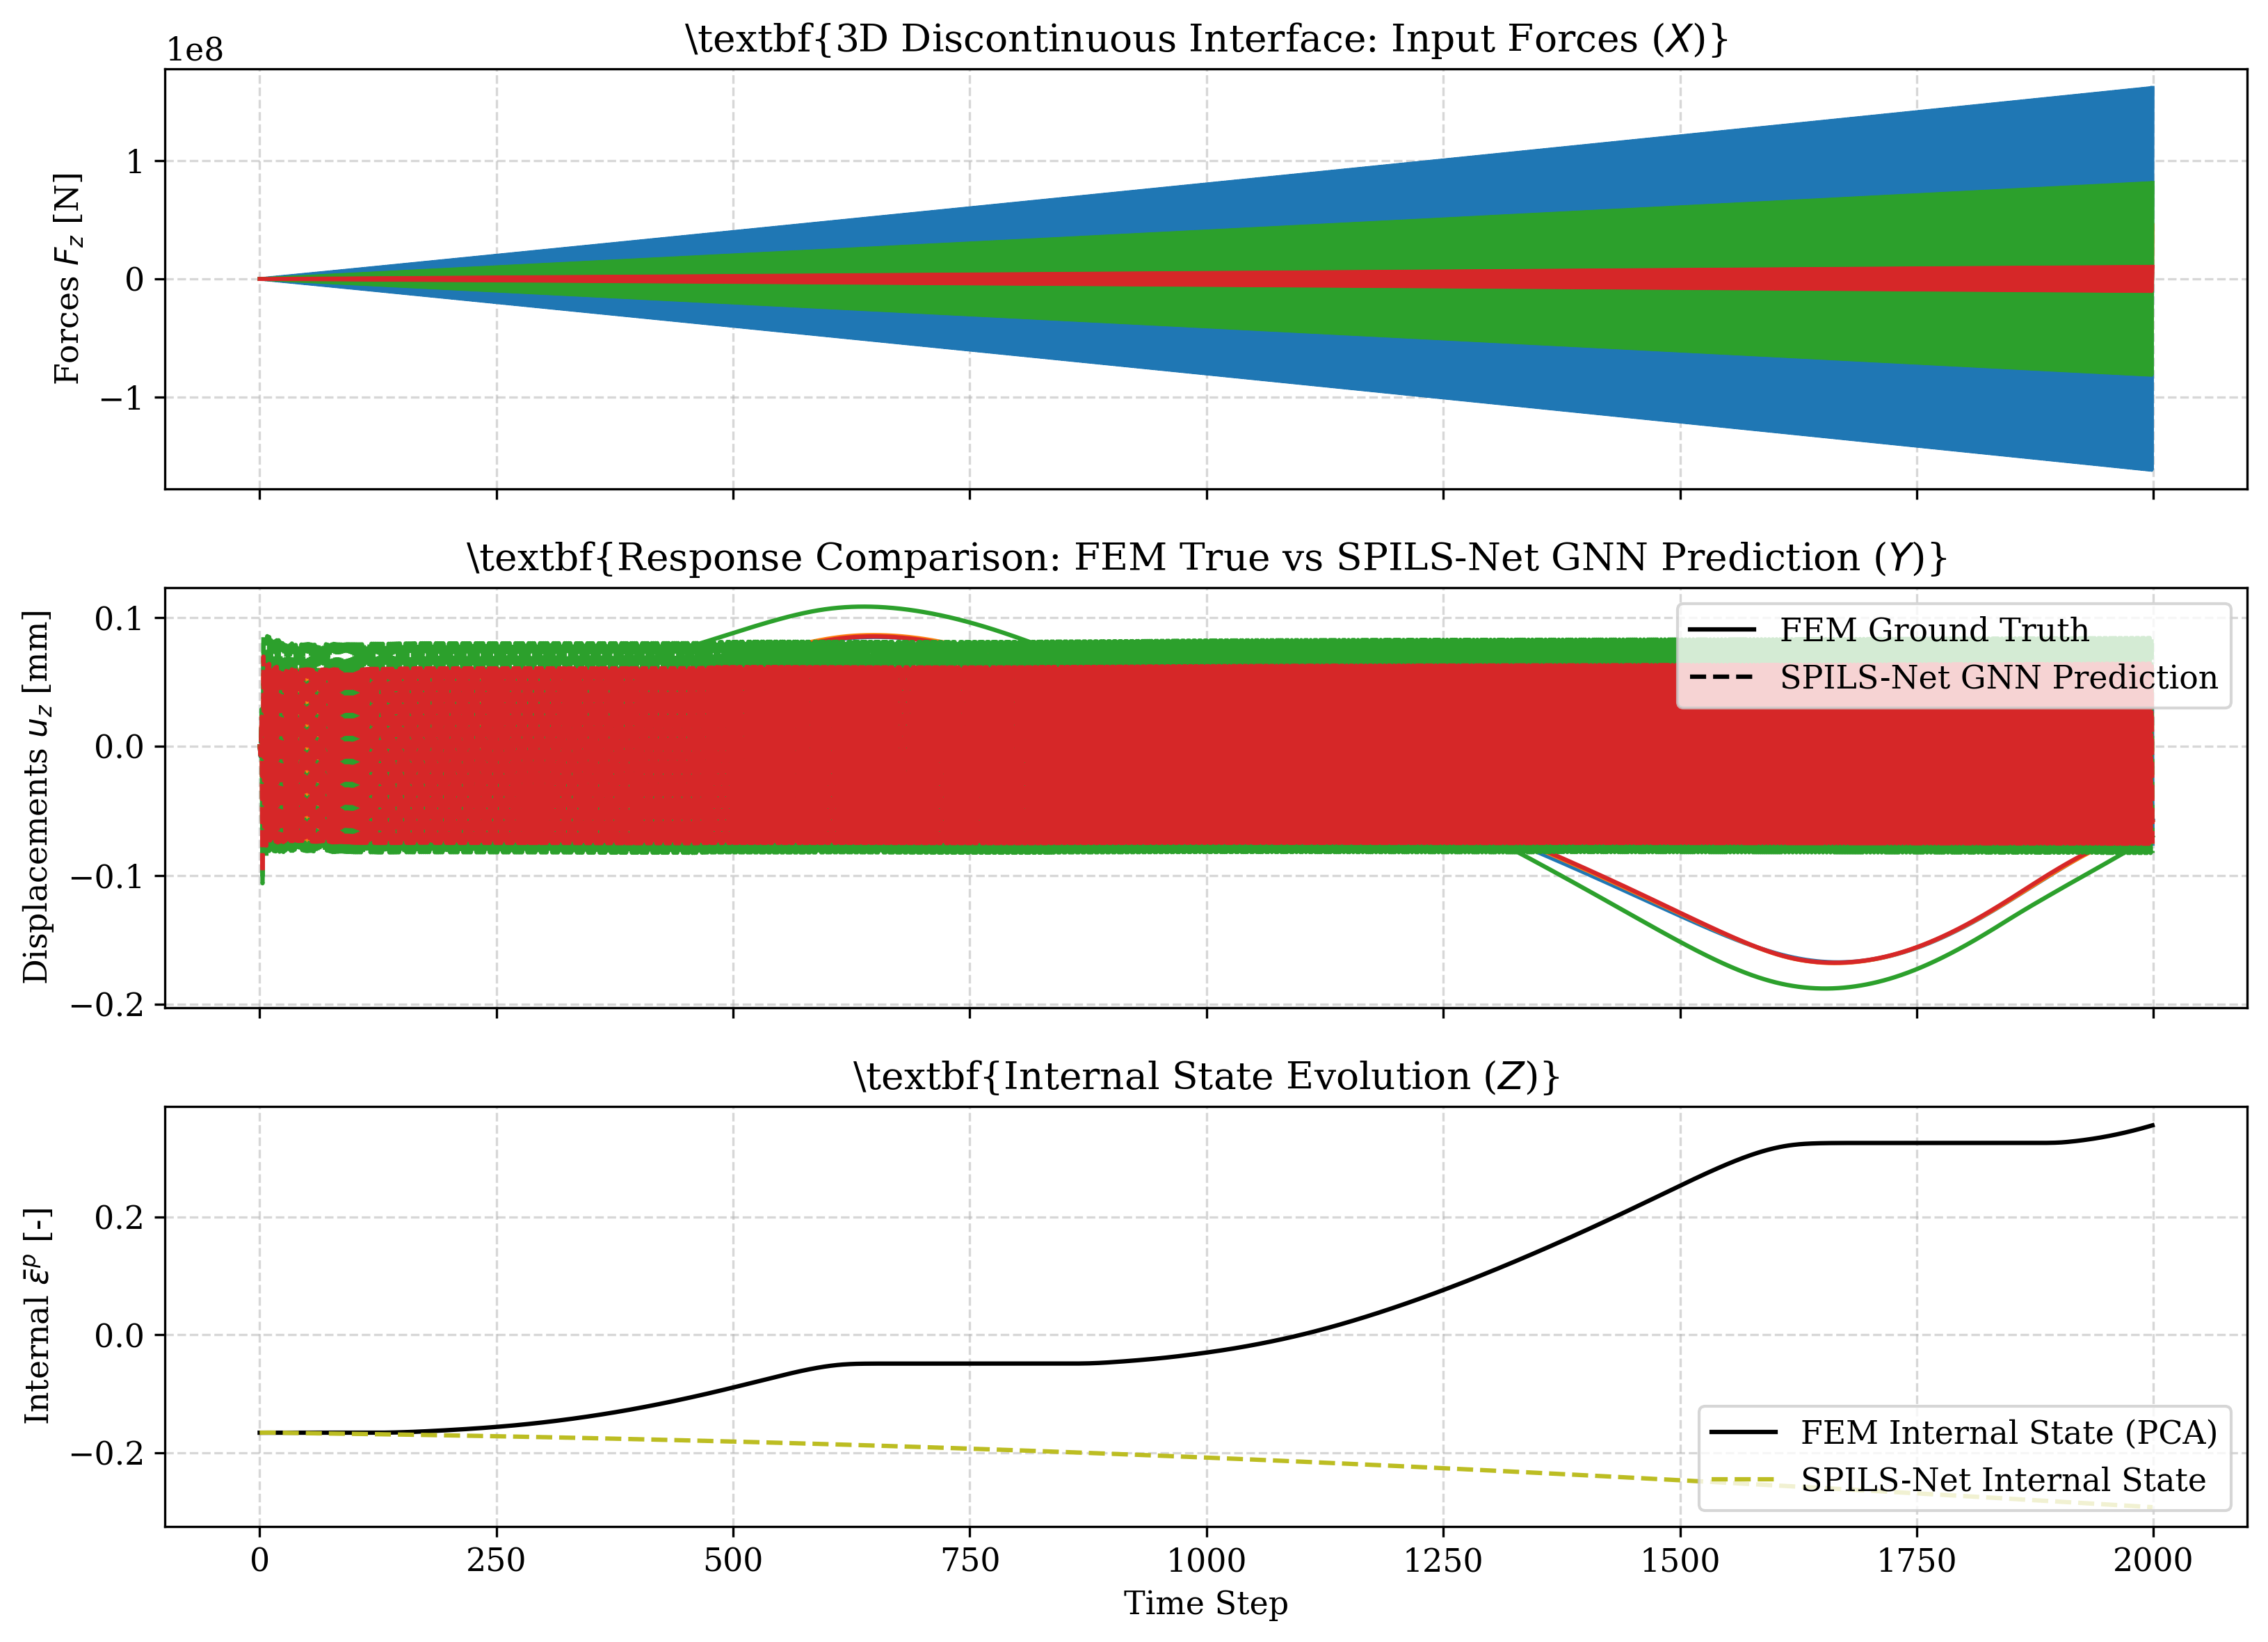

In [5]:
if node_coords is not None:
    left_idxs = np.where(node_coords[:, 0] < 0)[0]
    right_idxs = np.where(node_coords[:, 0] > 0)[0]
    chosen_nodes = [left_idxs[0], left_idxs[len(left_idxs)//2], right_idxs[0], right_idxs[len(right_idxs)//2]]
else:
    chosen_nodes = [0, 10, 20, 30]

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, dpi=300)

# 1. Input Forces (Z-component)
make_plot_3d(axes[0], sm_results_in, chosen_nodes, dof_offset=2, linestyle='-', linewidth=1.4)
axes[0].set_ylabel(r"Forces $F_z$ [N]")
axes[0].set_title(r"\textbf{3D Discontinuous Interface: Input Forces ($X$)}")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Displacements: Ground Truth vs Predicted (Z-component)
make_plot_3d(axes[1], tct_results_out, chosen_nodes, dof_offset=2, linestyle='-', linewidth=1.5, label="FEM Ground Truth")
make_plot_3d(axes[1], sm_results_out, chosen_nodes, dof_offset=2, linestyle='--', linewidth=1.5, label="SPILS-Net GNN")
axes[1].set_ylabel(r"Displacements $u_z$ [mm]")
axes[1].set_title(r"\textbf{Response Comparison: FEM True vs SPILS-Net GNN Prediction ($Y$)}")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Custom legend
fem_line = mlines.Line2D([], [], color='black', linestyle='-', label='FEM Ground Truth')
sm_line  = mlines.Line2D([], [], color='black', linestyle='--', label='SPILS-Net GNN Prediction')
axes[1].legend(handles=[fem_line, sm_line], loc='upper right', frameon=True)

# 3. Internal Plastic Strain State (Z)
if len(tct_results_internal) > 0 and np.any(tct_results_internal != 0):
    axes[2].plot(tct_results_internal, color='black', linestyle='-', label='FEM Internal State (PCA)')
    axes[2].plot(sm_results_internal, color=internal_state_color, linestyle='--', label='SPILS-Net Internal State')
    axes[2].legend(loc='lower right', frameon=True)
else:
    axes[2].plot(sm_results_internal, color=internal_state_color, linestyle='--', label='SPILS-Net Internal State')
axes[2].set_ylabel(r"Internal $\bar{\varepsilon}^p$ [-]")
axes[2].set_xlabel("Time Step")
axes[2].set_title(r"\textbf{Internal State Evolution ($Z$)}")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = Path("figures/06_spils_net_gnn_3d_disc_results_1000.pdf")
plt.savefig(fig_path, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

## 4. Relative Nodal Displacement Error Evolution ($e_n$ Over Time)

Saved figure: figures/06_3d_plastic_disc_error_evolution_1000.pdf


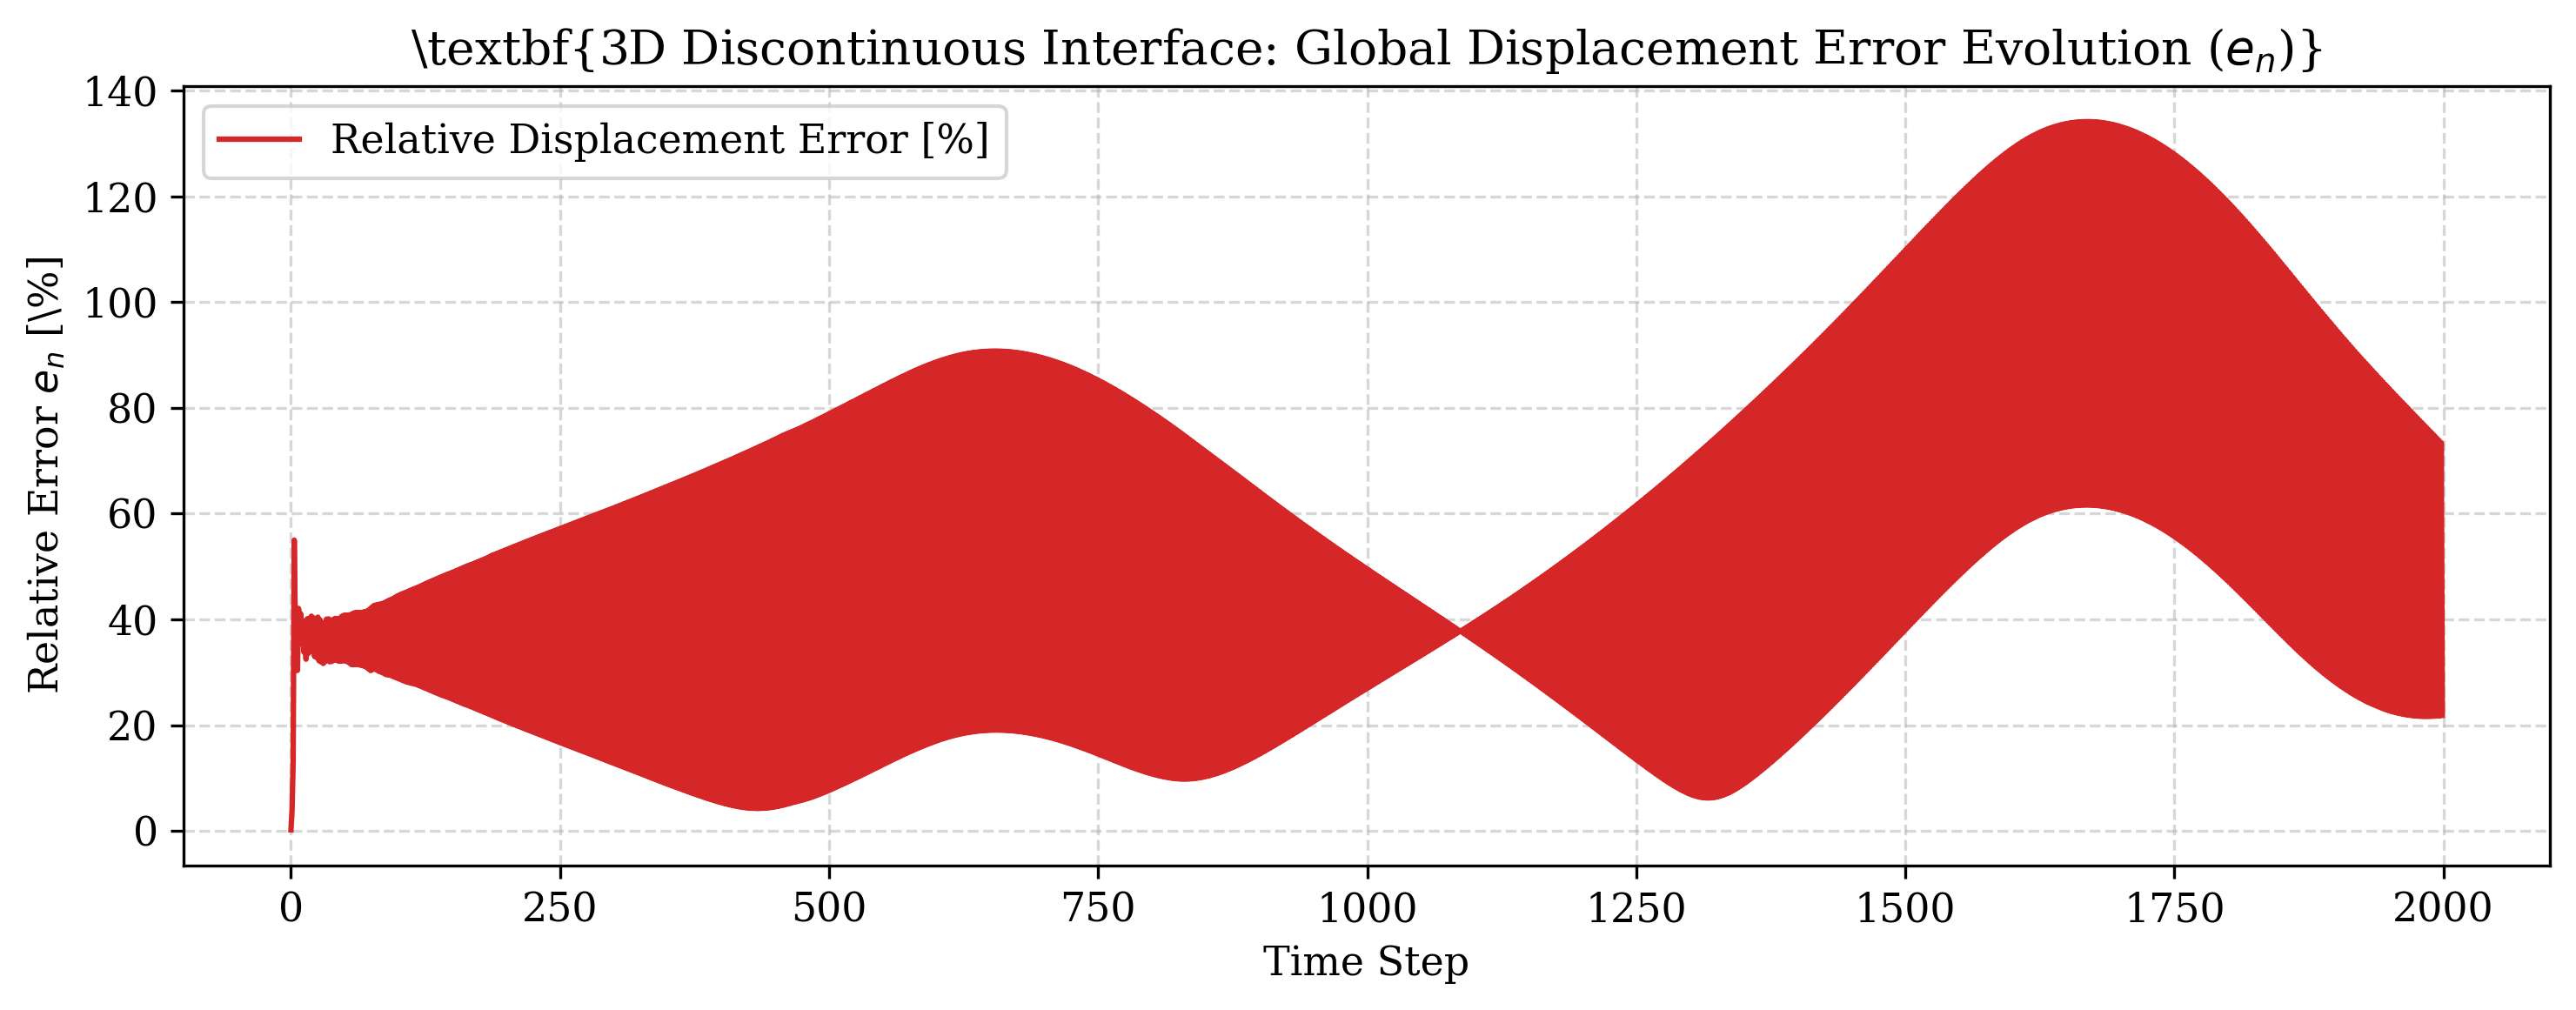

In [6]:
diff = tct_results_out - sm_results_out
truth_norm = np.linalg.norm(tct_results_out, axis=-1)
max_truth = max(float(np.max(truth_norm)), 1e-10)

step_errors = np.linalg.norm(diff, axis=-1) / max_truth * 100

fig, ax = plt.subplots(figsize=(10, 4), dpi=300)
ax.plot(step_errors, color="tab:red", linewidth=1.5, label="Relative Displacement Error [%]")
ax.set_title(r"\textbf{3D Discontinuous Interface: Global Displacement Error Evolution ($e_n$)}")
ax.set_xlabel("Time Step")
ax.set_ylabel(r"Relative Error $e_n$ [\%]")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
fig_path = Path("figures/06_3d_plastic_disc_error_evolution_1000.pdf")
plt.savefig(fig_path, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

## 5. Summary Performance Statistics

In [7]:
l2_diff = np.linalg.norm(diff)
l2_truth = np.linalg.norm(tct_results_out)
global_l2_rel_error = (l2_diff / max(l2_truth, 1e-12)) * 100
mean_step_error = np.mean(step_errors)
max_step_error = np.max(step_errors)

# Per-section errors
if node_coords is not None:
    left_dofs = np.concatenate([np.arange(i*3, i*3+3) for i in left_idxs])
    right_dofs = np.concatenate([np.arange(i*3, i*3+3) for i in right_idxs])
    
    err_left = (np.linalg.norm(diff[:, left_dofs]) / max(np.linalg.norm(tct_results_out[:, left_dofs]), 1e-12)) * 100
    err_right = (np.linalg.norm(diff[:, right_dofs]) / max(np.linalg.norm(tct_results_out[:, right_dofs]), 1e-12)) * 100
else:
    err_left = global_l2_rel_error
    err_right = global_l2_rel_error

print("=" * 65)
print("  3D DISCONTINUOUS SPILS-NET GNN PERFORMANCE SUMMARY")
print("=" * 65)
print(f"  Global L2 Relative Error       : {global_l2_rel_error:.4f} %")
print(f"  Mean Step-wise Error          : {mean_step_error:.4f} %")
print(f"  Maximum Step-wise Error       : {max_step_error:.4f} %")
print(f"  Section 1 (Left Side) Error   : {err_left:.4f} %")
print(f"  Section 2 (Right Side) Error  : {err_right:.4f} %")
print("=" * 65)

  3D DISCONTINUOUS SPILS-NET GNN PERFORMANCE SUMMARY
  Global L2 Relative Error       : 123.2527 %
  Mean Step-wise Error          : 51.8518 %
  Maximum Step-wise Error       : 134.1278 %
  Section 1 (Left Side) Error   : 123.1434 %
  Section 2 (Right Side) Error  : 123.3605 %
